In [1]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [2]:
data = load_breast_cancer()
# data

In [3]:
X = data['data']
y = data['target']

In [4]:
type(X)

numpy.ndarray

In [5]:
X.shape

(569, 30)

In [6]:
std = StandardScaler()
X = std.fit_transform(X)

In [7]:
cov = np.cov(X,rowvar=False)

In [8]:
cov.shape

(30, 30)

In [9]:
eigenVal, eigenVec = np.linalg.eig(cov)

In [10]:
eigenVal.shape, eigenVec.shape

((30,), (30, 30))

In [11]:
sortind = np.argsort(eigenVal)[::-1]

In [14]:
arr = np.array([2,1,3,41,5]) 
arr[[2,1]] #fancy indexing 

array([3, 1])

In [15]:
eigenVec = eigenVec[:,sortind]

In [17]:
d = 10 #dimensions

In [18]:
egv = eigenVec[:,:d]
egv.shape

(30, 10)

In [19]:
new_Data = X@egv #dot pdt with eigen vectors
new_Data.shape

(569, 10)

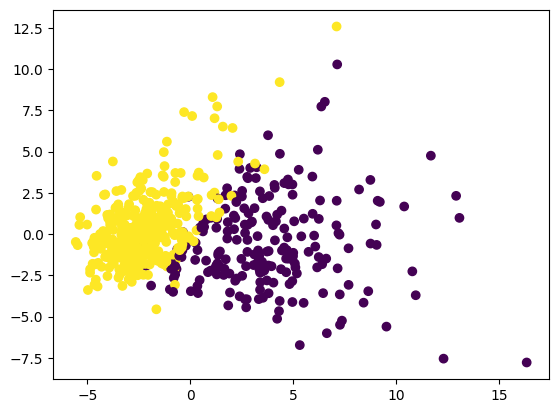

In [22]:
plt.scatter(new_Data[:,0],new_Data[:,1],c = y)

In [23]:
print(np.round(eigenVal[sortind]/np.sum(eigenVal),3)) #gives the percentage of each feature 

[0.443 0.19  0.094 0.066 0.055 0.04  0.023 0.016 0.014 0.012 0.01  0.009
 0.008 0.005 0.003 0.003 0.002 0.002 0.002 0.001 0.001 0.001 0.001 0.001
 0.001 0.    0.    0.    0.    0.   ]


In [24]:
print(np.cumsum(eigenVal[sortind])/np.sum(eigenVal)) #cummulative sum and tells the data captured in a cummulative manner
#tells how much data loss. 85% + data captured is considered good

[0.44272026 0.63243208 0.72636371 0.79238506 0.84734274 0.88758796
 0.9100953  0.92598254 0.93987903 0.95156881 0.961366   0.97007138
 0.97811663 0.98335029 0.98648812 0.98915022 0.99113018 0.99288414
 0.9945334  0.99557204 0.99657114 0.99748579 0.99829715 0.99889898
 0.99941502 0.99968761 0.99991763 0.99997061 0.99999557 1.        ]


In [25]:
from sklearn.decomposition import PCA

In [26]:
pca = PCA(n_components=2) 
newD = pca.fit_transform(X)

In [27]:
newD.shape

(569, 2)

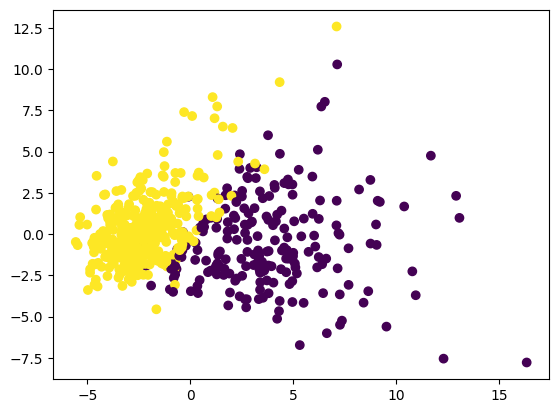

In [28]:
plt.scatter(newD[:,0],newD[:,1],c = y)

In [30]:
pca.components_ #tells eigen vectors only

array([[ 0.21890244,  0.10372458,  0.22753729,  0.22099499,  0.14258969,
         0.23928535,  0.25840048,  0.26085376,  0.13816696,  0.06436335,
         0.20597878,  0.01742803,  0.21132592,  0.20286964,  0.01453145,
         0.17039345,  0.15358979,  0.1834174 ,  0.04249842,  0.10256832,
         0.22799663,  0.10446933,  0.23663968,  0.22487053,  0.12795256,
         0.21009588,  0.22876753,  0.25088597,  0.12290456,  0.13178394],
       [-0.23385713, -0.05970609, -0.21518136, -0.23107671,  0.18611302,
         0.15189161,  0.06016536, -0.0347675 ,  0.19034877,  0.36657547,
        -0.10555215,  0.08997968, -0.08945723, -0.15229263,  0.20443045,
         0.2327159 ,  0.19720728,  0.13032156,  0.183848  ,  0.28009203,
        -0.21986638, -0.0454673 , -0.19987843, -0.21935186,  0.17230435,
         0.14359317,  0.09796411, -0.00825724,  0.14188335,  0.27533947]])

In [33]:
pca.explained_variance_ #absolute amount of variance captured by each principal component

array([13.30499079,  5.7013746 ])

In [34]:
pca.explained_variance_ratio_   #proportion (percentage) of the total variance that each component accounts for

array([0.44272026, 0.18971182])